# Geometrie und Trigonometrie

## 06 - Geometrische Flächenformeln und Herleitungen

Oft lernt man in der Schule klassisch auswendig: "Grundseite mal Höhe". Aber warum?
Warum spielt der Winkel beim Parallelogramm scheinbar keine Rolle für die Fläche, solange die Höhe gleich bleibt?

In diesem Notebook werden wir einige mächtige Konzepte der Mathematik kennenlernen:
1. **Das Zerlegungsprinzip:** Wenn ich eine Figur zerschneide und neu zusammensetze, bleibt die Fäche gleich.
2. **Das Prinzip von Cavalieri (Scherung):** Wenn zwei Körper in jeder Höhe gleich breite Querschnitte haben, ist ihr Volumen (oder hier: ihre Fläche) gleich.
3. **Die Exhaustionsmethode (Ausschöpfung):** Wie wir Kurven (Kreise) berechnen, indem wir sie durch Geraden annähern.

**Lernziele:**
- Du verstehst die **Herleitung** der Flächenformeln für Parallelogramm, Dreieck, und Trapez.
- Du verstehst das Konzept der **Hohe** als orthogonalem Abstand.
- Du lernst, wie die Kreiszahl $\pi$ durch **Grenzwertprozess** definiert ist.

### 1. Das Axiom: Das Rechteck

In der Mathematik müssen wir uns auf eine grundlegende Wahrheit einigen, die wir nicht beweisen, sondern *setzen* (ein Axiom).

**Definition:**
Der Flächeninhalt $A$ eines Rechtecks mit den Seitenlängen $a$ und $b$ ist definiert als das Produkt der Seiten.

$$A = a \cdot b$$

*Warum?* Weil wir Fläche als "Anzahl der Einheitsquadrate" $(1 \times 1)$ definieren, die in die Form passen.

---

### 2. Das Parallelogramm & die Scherung

Ein Parallelogramm ist ein Viereck, bei dem gegenüberliegende Seiten parallel sind.
Die klassische Formel lautet $A = g \cdot h$ (Grundfläche mal Höhe), oder auch $A = a \cdot h_a$ (Seite $a$ mal Höhe auf $a$). Aber warum taucht die schräge Seite $b$ hier nicht auf?

**Der Beweis durch Zerlegung:**
Wir können links ein rechtwinkliges Dreieck abschneiden und es rechts wieder anfügen. Aus dem schiefen Parallelogramm wird ein perfektes Rechteck mit der Breite $a$ und der Höhe $h_a$.

**Das Prinzip von Cavalieri:**
Stellen wir uns ein Parallelogramm als einen Stapel Spielkarten - betrachtet von der Seite vor. Wenn man den Stapel zur Seite drückt (schert), ändert sich die Form des Stapels, aber das **Volumen** bleibt exakt gleich (hierbei bilden die Kanten des Stapels ein Parallelogramm - die Fläche dessen gleich bleiben muss, wenn das Volumen gleich bleibt). 

In [3]:
# Settings für Parallelogramm Visualisierung
Para_Config = {
    "g": 4.0,          # Grundseite
    "h": 3.0,          # Höhe
    "shear": 2.5,      # Wie schief? (Versatz der oberen Seite)
    "figsize": (8, 5),
    "color": "skyblue",
    "color_cut": "orange"
}

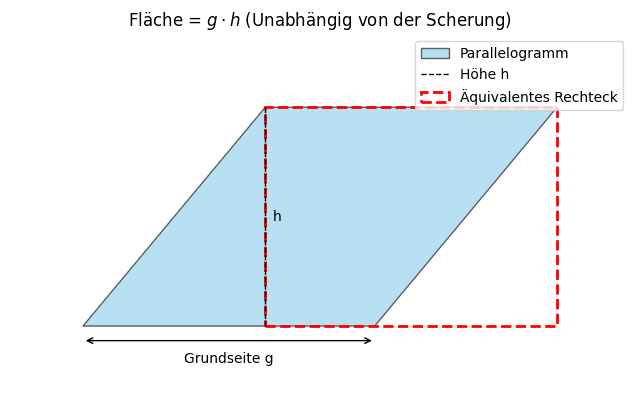

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np


def plot_parallelogram_proof(ax, cfg):
    g = cfg["g"]
    h = cfg["h"]
    s = cfg["shear"]
    
    # Koordinaten Parallelogramm
    # Unten links (0,0), Unten rechts (g,0)
    # Oben links (s, h), Oben rechts (g+s, h)
    coords = [(0, 0), (g, 0), (g + s, h), (s, h)]
    
    # Parallelogramm zeichnen
    poly = patches.Polygon(coords, closed=True, facecolor=cfg["color"], edgecolor='black', alpha=0.6, label='Parallelogramm')
    ax.add_patch(poly)
    
    # Das "abgeschnittene" Dreieck links (virtuell, um es zu zeigen)
    # Dreieck Punkte: (0,0), (s,0), (s,h) -> Nein, das ist nicht das Dreieck des Parallelogramms.
    # Das Dreieck wird durch die Höhe definiert.
    # Wir fällen das Lot von Oben Links (s,h) auf die x-Achse -> Punkt (s,0).
    # Das linke Dreieck ist: (0,0) -> (s,0) -> (s,h). Moment, (s,h) ist oben links.
    # Das Parallelogramm geht von (0,0) zu (s,h). 
    
    # Eingezeichnete Höhe h
    ax.plot([s, s], [0, h], 'k--', lw=1, label='Höhe h')
    ax.text(s + 0.1, h/2, 'h', va='center')
    
    # Das Dreieck, das wir "abschneiden" (links)
    # Punkte: (0,0), (s,0), (s,h) ... Das wäre ein Dreieck INNERHALB, wenn s>0.
    # Der Beweis funktioniert so: Man fällt das Lot von oben links.
    
    # Visualisierung des Rechtecks, das entsteht:
    rect = patches.Rectangle((s, 0), g, h, linewidth=2, edgecolor='red', facecolor='none', linestyle='--', label='Äquivalentes Rechteck')
    ax.add_patch(rect)
    
    # Das Dreieck rechts, das "hinzugefügt" wird
    tri_right_coords = [(g, 0), (g+s, 0), (g+s, h)] # Das macht keinen Sinn bei Scherung.
    
    # Einfacherer visueller Beweis:
    # Wir zeigen, dass Fläche = g * h.
    ax.annotate('', xy=(0, -0.2), xytext=(g, -0.2), arrowprops=dict(arrowstyle='<->'))
    ax.text(g/2, -0.5, 'Grundseite g', ha='center')
    
    ax.set_xlim(-1, g + s + 1)
    ax.set_ylim(-1, h + 1)
    ax.set_aspect('equal')
    ax.legend(loc='upper right')
    ax.set_title(r"Fläche = $g \cdot h$ (Unabhängig von der Scherung)")
    ax.axis('off')

fig, ax = plt.subplots(figsize=Para_Config["figsize"])
plot_parallelogram_proof(ax, Para_Config)
plt.show()

### 3. Animation: Scherung

Die untenstehende Animation veranschaulicht das Prinzp der Scherung weiter.
Wir starten mit einem Rechteck ($A = g \cdot h$) und schieben die obere Seite zur Seite
Die Grundseite $g$ bleibt gleich. Die Höhe $h$ bleibt gleich. Also muss auch die Fläche gleich bleiben, egal wie "schief" das Parallelogramm wird.

In [5]:
# Animation Settings
Shear_Anim_Config = {
    "g": 4.0,
    "h": 3.0,
    "max_shear": 5.0,
    "frames": 60,
    "interval": 40
}

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animate_shear(cfg):
    g, h = cfg["g"], cfg["h"]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_xlim(-1, g + cfg["max_shear"] + 1)
    ax.set_ylim(-1, h + 1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_title("Prinzip von Cavalieri: Scherung ändert die Fläche nicht")

    # Polygon (initial als Rechteck)
    poly = patches.Polygon([(0,0), (g,0), (g,h), (0,h)], closed=True, facecolor='skyblue', edgecolor='black', alpha=0.6)
    ax.add_patch(poly)

    # Höhenlinie (bleibt konstant)
    line_h = ax.plot([], [], 'r--', lw=1.5, label='Höhe h (konstant)')[0]

    # Text
    txt = ax.text(g/2, -0.8, f"Fläche = {g*h:.2f}", ha='center', fontsize=12)

    def update(frame):
        # Sinus-Bewegung für sanften Loop
        progress = (1 + np.sin(frame * 2 * np.pi / cfg["frames"] - np.pi/2)) / 2 
        current_s = progress * cfg["max_shear"]
        
        # Neue Koordinaten
        # Unten bleibt fix: (0,0), (g,0)
        # Oben wandert: (current_s, h), (g + current_s, h)
        new_xy = np.array([
            [0, 0],
            [g, 0],
            [g + current_s, h],
            [current_s, h]
        ])
        poly.set_xy(new_xy)
        
        # Höhenlinie einzeichnen (an der neuen linken Kante herunter)
        # Von (current_s, h) runter auf (current_s, 0) wäre die Höhe, 
        # aber wir zeichnen sie lieber fix ein, um zu zeigen dass h gleich bleibt.
        # Wir zeichnen sie bei x=g (rechts)
        # line_h.set_data([g + current_s, g + current_s], [0, h]) -> Das ist schief.
        # Höhe ist der orthogonale Abstand. Wir zeichnen eine Linie bei x=0 (virtuell)
        
        return poly, txt

    anim = FuncAnimation(fig, update, frames=cfg["frames"], blit=True, interval=cfg["interval"])
    plt.close()
    return anim

anim = animate_shear(Shear_Anim_Config)
HTML(anim.to_jshtml())

### 4. Das Dreieck

Jedes beliebige Dreieck lässt sich durch Spiegelung an einer der Seitenmitten zu einem Parallelogramm verdoppeln.
- Das entstandene Parallelogramm hat die Grundseite $g$ und die Höhe $h$.
- Seine Fläche ist $A_{\text{Para}} = g \cdot h$.
- Da das Dreieck genau die Hälfte davon ist:

$$A_{\text{Dreieck}} = \frac{1}{2} \cdot g \cdot h$$

*Wichtige Erkenntnis:* Es ist egal, wo die Spitze des Dreiecks liegt (solange sie auf einer Paralleln zur Grundseite verschoben wird), die Fläche bleibt gleich.

---


### 5. Das Trapez

Ein Trapez hat zwei parallele Seiten $a$ und $c$. Die anderen beiden Seiten sind beliebig.
Um die Formel zu beweisen, gibt es einen eleganten Trick:
Wir verdoppeln das Trapez und legen das zweite verkehrt herum an das erste.

- Es entsteht ein riesiges Parallelogramm.
- Die Grundseite dieses Parallelogramms ist $(a + c)$.
- Die Höhe ist $h$.
- Fläche des Parallelogramms: $A_{\text{Gesamt}} = (a + c) \cdot h$.
- Da wir zwei Trapeze haben, ist die Fläche eines einzelnen:

$$A_{\text{Trapez}} = \frac{a + c}{2} \cdot h$$

Der Term $\frac{a+c}{2}$ ist dabei nichts anderes als die **Mittelparallele** $m$ (der Durchschnitt der beiden Längen).

### 6. Der Kreis: Die Ausschöpfung

Wie berechnet man die Fläche von etwas, das keine Ecken hat? Die antiken Griechen (besonders Archimedes) nutzten die **Exhaustionsmethode**.

Wir nähern den Kreis durch regelmäßige Vielecke an ($n$-Ecke).
- Ein 4-Eck (Quadrat) ist eine grobe Näherung.
- Ein 8-Eck ist besser.
- Ein 100-Eck ist fast nicht mehr von einem Kreis zu unterscheiden.

**Die Herleitung:**
Zerlegen wir ein regelmäßiges $n$-Eck in $n$ Dreiecke.
Jedes Dreieck hat die Grundseite $s$ (Seitenlänge des Polygons) und die Höhe $h$ (Abstand zum Mittelpunkt).
$$A_{\text{Dreieck}} = \frac{1}{2} \cdot s \cdot h$$

Die Gesamtfläche des Polygons ist:
$$A_n = n \cdot \left( \frac{1}{2} \cdot s \cdot h \right) = \frac{1}{2} \cdot (n \cdot s) \cdot h$$

Der Term $(n \cdot s)$ ist der **Umfang** $U$ des Polygons.
$$A_n = \frac{1}{2} \cdot U \cdot h$$

Wenn $n$ unendlich groß wird ($n \to \infty$):
1.  Der Umfang $U$ wird zum Kreisumfang $2\pi r$.
2.  Die Höhe $h$ wird zum Radius $r$.

Einsetzen:
$$A_{\text{Kreis}} = \frac{1}{2} \cdot (2\pi r) \cdot r = \pi r^2$$

Dies ist einer der ersten historischen Beweise, der Grenzwertbetrachtungen (Calculus) vorwegnahm.

In [18]:
# Animation: Archimedes Annäherung

Circle_Anim_Cfg = {
    "radius": 1.0,
    "n_start": 3,
    "n_end": 25, # Wir gehen bis zum 20-Eck
    "frames": 120,
    "interval": 200, # Langsam, damit man es sieht
    "color_poly": "orange",
    "color_circle": "blue"
}

In [19]:
def animate_circle_approx(cfg):
    r = cfg["radius"]
    
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(r"Annäherung: $A = \frac{1}{2} \cdot U \cdot h \rightarrow r^2\pi$")
    
    # Der "wahre" Kreis (Hintergrund)
    circle = patches.Circle((0, 0), r,fill=False, edgecolor=cfg["color_circle"], lw=2, linestyle='--', label='Kreis')
    ax.add_patch(circle)
    
    # Das Polygon
    poly_patch = patches.Polygon([(0,0)], closed=True, fc=cfg["color_poly"], alpha=0.5, ec='black')
    ax.add_patch(poly_patch)
    
    # Text
    txt_n = ax.text(0, -1.3, "", ha='center', fontsize=12)
    txt_err = ax.text(0, -1.45, "", ha='center', fontsize=10, color='red')

    # Wir berechnen eine Liste von n-Werten, die wir zeigen wollen
    # Wir wollen bei 3 starten und dann hochzählen
    n_values = list(range(cfg["n_start"], cfg["n_end"] + 1))
    
    def init():
        return poly_patch, txt_n, txt_err
    
    def update(frame_idx):
        # Da frames mehr sein können als n_values, mappen wir
        n = n_values[min(frame_idx, len(n_values)-1)]
        
        # Polygon Ecken berechnen
        # Wir teilen den Kreis in n Tortenstücke
        angles = np.linspace(0, 2*np.pi, n, endpoint=False)
        # Koordinaten (x, y)
        # r ist hier der Radius des Umkreises des Polygons
        x = r * np.cos(angles)
        y = r * np.sin(angles)
        xy = np.column_stack((x, y))
        
        poly_patch.set_xy(xy)
        
        # Flächenberechnung
        # Fläche n-Eck = 0.5 * n * r^2 * sin(2pi/n)
        area_poly = 0.5 * n * r**2 * np.sin(2*np.pi/n)
        area_circle = np.pi * r**2
        error = 100 * (area_circle - area_poly) / area_circle
        
        txt_n.set_text(f"Ecken n = {n}")
        txt_err.set_text(f"Fehler zur Kreisfläche: {error:.2f}%")
        
        return poly_patch, txt_n, txt_err

    anim = FuncAnimation(fig, update, frames=len(n_values), blit=True, interval=cfg["interval"])
    plt.close()
    return anim

anim = animate_circle_approx(Circle_Anim_Cfg)
HTML(anim.to_jshtml())

### Übungsaufgaben

**Aufgabe 1: Die Hauswand**
Eine Hauswand hat die Form eines Rechtecks (Breite 6m, Höhe 3m) mit einem aufgesetzten Giebeldreieck. Die Gesamthöhe bis zur Spitze beträgt 5m.
Berechne die Gesamtfläche der Wand.
*(Tipp: Wie hoch ist das Dreieck alleine?)*

**Aufgabe 2: Der Kreisring**
Berechne die Fläche eines Kreisrings (wie eine Unterlegscheibe).
Außenradius $R = 5$ cm, Innenradius $r = 3$ cm.
Leite eine allgemeine Formel her.

**Aufgabe 3: Umkehrung**
Ein Dreieck hat eine Fläche von $24 \text{ cm}^2$ und eine Grundseite von $8 \text{ cm}$.
Berechne die Höhe $h$.

---
### Glossar (Deutsch - Englisch)

- **Flächeninhalt:** Area
- **Umfang:** Perimeter (Polygon) / Circumference (Circle)
- **Rechteck:** Rectangle
- **Parallelogramm:** Parallelogram
- **Trapez:** Trapezoid (US) / Trapezium (UK)
- **Kreis:** Circle
- **Radius:** Radius
- **Prinzip von Cavalieri:** Cavalieri's principle
- **Scherung:** Shear mapping
- **Exhaustionsmethode:** Method of exhaustion